<a href="https://colab.research.google.com/github/San-Maansson/Stock_Analysis/blob/main/Stock_market_screener.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install TA-Lib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 26.6 MB/s eta 0:00:00


In [5]:
import pandas as pd
import numpy as np
import yfinance as yf
import talib as ta
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

In [12]:
# This line is only valid in Jupyter Notebook. Remove or comment it out if running as a .py file.
%matplotlib inline

# Dow30 tickers
tickers = [
    "AAPL", "AMGN", "AXP", "BA", "CAT", "CRM", "CSCO", "CVX", "DIS", "DOW",
    "GS", "HD", "HON", "IBM", "INTC", "JNJ", "JPM", "KO", "MCD", "MMM",
    "MRK", "MSFT", "NKE", "PG", "TRV", "UNH", "V", "VZ", "WBA", "WMT"
]

# Download historical stock data
start_date = '2025-02-01'
end_date = '2025-09-30'  # or use dt.datetime.today().strftime('%Y-%m-%d')

data = yf.download(
    tickers,
    start=start_date,
    end=end_date,
    group_by='ticker',
    auto_adjust=True,
    threads=True
)

# Scoring Functions
def ma50_score(df):
    ma50_series = ta.SMA(df['Close'], timeperiod=50)
    ma200_series = ta.SMA(df['Close'], timeperiod=200)

    if len(ma50_series.dropna()) < 6 or len(ma200_series.dropna()) == 0:
        return 0  # Not enough data

    ma50 = ma50_series.iloc[-1]
    ma50_5ago = ma50_series.iloc[-5]
    ma200 = ma200_series.iloc[-1]
    close = df['Close'].iloc[-1]

    dist = (close - ma50) / ma50
    dist_score = np.clip(dist, -1, 1)

    slope = (ma50 - ma50_5ago) / ma50
    slope_score = np.clip(slope * 5, -1, 1)

    regime = 1 if ma50 > ma200 else -1

    score = 0.5 * dist_score + 0.3 * slope_score + 0.2 * regime
    return np.clip(score, -1, 1)

def rsi_score_momentum(df, rsi_period=14, lookback=20):
    rsi_series = ta.RSI(df['Close'], timeperiod=rsi_period)
    rsi_change = rsi_series.diff()

    if len(rsi_change.dropna()) < lookback:
        return 0

    change = rsi_change.iloc[-1]
    stdev = rsi_change.rolling(lookback).std().iloc[-1]

    if pd.isna(stdev) or stdev == 0:
        return 0

    score = change / (2 * stdev)
    return np.clip(score, -1, 1)

def vol_score(df, lookback_vol=20):
    if len(df) < lookback_vol + 2:
        return 0

    avg_vol = df['Volume'].rolling(window=lookback_vol).mean().iloc[-1]
    curr_vol = df['Volume'].iloc[-1]
    ratio = curr_vol / avg_vol if avg_vol != 0 else 0
    ratio = min(ratio, 1.0)

    price_diff = df['Close'].iloc[-1] - df['Close'].iloc[-2]
    trend_sign = np.sign(price_diff)

    return ratio * trend_sign

# Main loop
results = []

for ticker in tickers:
    try:
        df_ticker = data[ticker][['Close', 'Volume']].dropna()

        result = {
            'Ticker': ticker,
            'ma50_score': ma50_score(df_ticker),
            'rsi_score': rsi_score_momentum(df_ticker),
            'vol_score': vol_score(df_ticker),
        }

        result['final_score'] = np.mean([result['ma50_score'], result['rsi_score'], result['vol_score']])
        results.append(result)

    except Exception as e:
        print(f"Error processing {ticker}: {e}")
        continue

scanner_df = pd.DataFrame(results)
scanner_df = scanner_df.sort_values('final_score', ascending=False).reset_index(drop=True)

[*********************100%***********************]  30 of 30 completed


In [13]:
# Display top results
print(scanner_df.head())
scanner_df

  Ticker  ma50_score  rsi_score  vol_score  final_score
0    DIS           0   0.754847    1.00000     0.584949
1    HON           0   0.555389    1.00000     0.518463
2     PG           0   0.447487    1.00000     0.482496
3    CAT           0   0.412489    1.00000     0.470830
4     KO           0   0.614881    0.78877     0.467884


,Ticker,ma50_score,rsi_score,vol_score,final_score
0,DIS,0,7.548465e-01,1.000000,5.849488e-01
1,HON,0,5.553886e-01,1.000000,5.184629e-01
2,PG,0,4.474870e-01,1.000000,4.824957e-01
3,CAT,0,4.124892e-01,1.000000,4.708297e-01
4,KO,0,6.148810e-01,0.788770,4.678837e-01
5,JNJ,0,3.989737e-01,1.000000,4.663246e-01
6,V,0,3.242614e-01,1.000000,4.414205e-01
7,NKE,0,2.405926e-01,1.000000,4.135309e-01
8,CSCO,0,4.464261e-01,0.759722,4.020493e-01
9,MSFT,0,2.863574e-01,0.871527,3.859615e-01


/tmp/ipython-input-3099601719.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Ticker', y='final_score', data=scanner_df, palette='coolwarm')


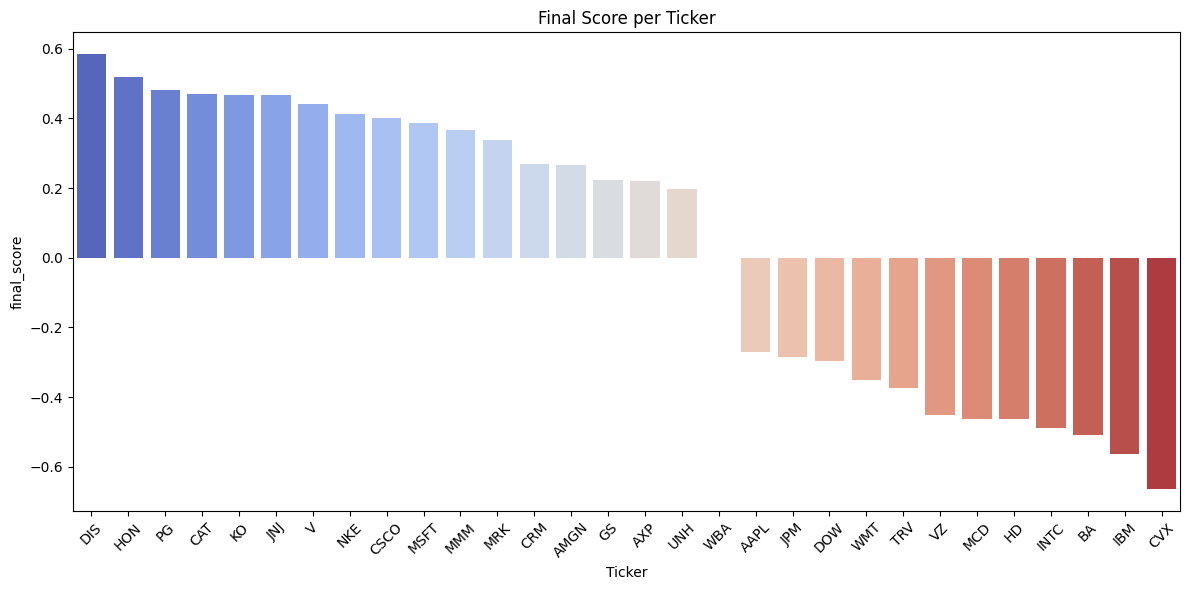

In [14]:
# Bar Chart
plt.figure(figsize=(12, 6))
sns.barplot(x='Ticker', y='final_score', data=scanner_df, palette='coolwarm')
plt.title('Final Score per Ticker')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

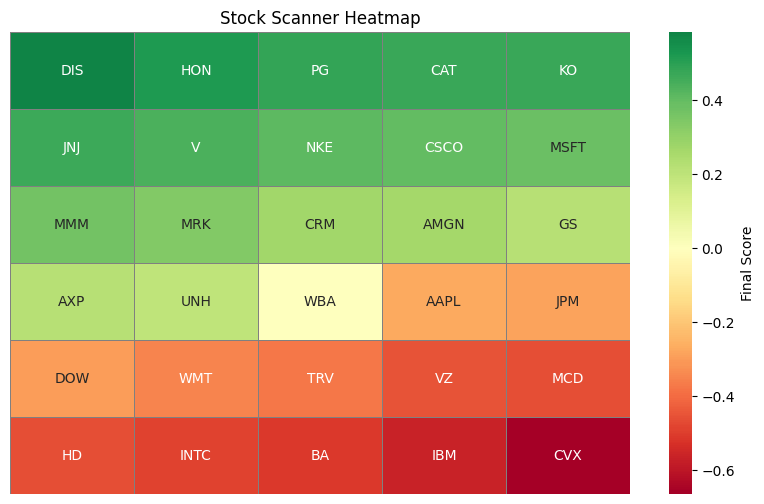

In [15]:
# Heatmap
values = scanner_df['final_score'].values
n = len(values)
rows = int(np.ceil(np.sqrt(n)))
cols = int(np.ceil(n / rows))

grid = np.full((rows, cols), np.nan)
labels = np.full((rows, cols), "", dtype=object)

for i, val in enumerate(values):
    r = i // cols
    c = i % cols
    grid[r, c] = val
    labels[r, c] = scanner_df['Ticker'].iloc[i]

plt.figure(figsize=(10, 6))
sns.heatmap(grid,
            annot=labels,
            fmt='',
            center=0,
            cmap='RdYlGn',
            cbar_kws={'label': 'Final Score'},
            linewidths=0.5,
            linecolor='gray')
plt.title('Stock Scanner Heatmap')
plt.yticks([])
plt.xticks([])
plt.show()

In [16]:
# Example data preview
print(data['MSFT'].tail())

Price             Open        High         Low       Close    Volume
Date                                                                
2025-09-23  513.799988  514.590027  507.309998  509.230011  19799600
2025-09-24  510.380005  512.479980  506.920013  510.149994  13533700
2025-09-25  508.299988  510.010010  505.040009  507.029999  15786500
2025-09-26  510.059998  513.940002  506.619995  511.459991  16213100
2025-09-29  511.500000  516.849976  508.880005  514.599976  17617800
